<a href="https://colab.research.google.com/github/dudekulapeeravali2537sse-bot/ITA0616/blob/main/EXP_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 rows of dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dataset Shape: (150, 5)

Model Accuracy: 93.33%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      

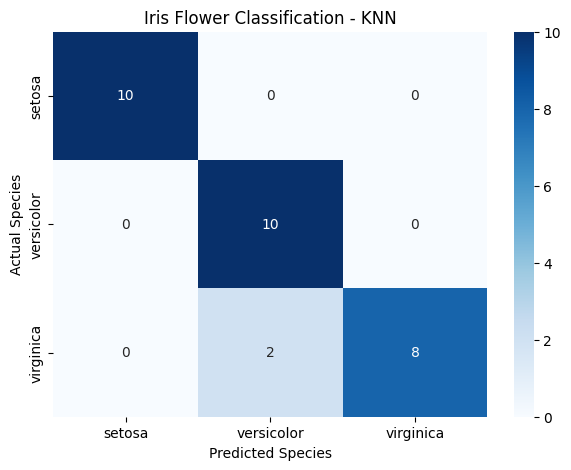


New Flower Measurements: [[5.1 3.5 1.4 0.2]]
Predicted Flower Species: setosa


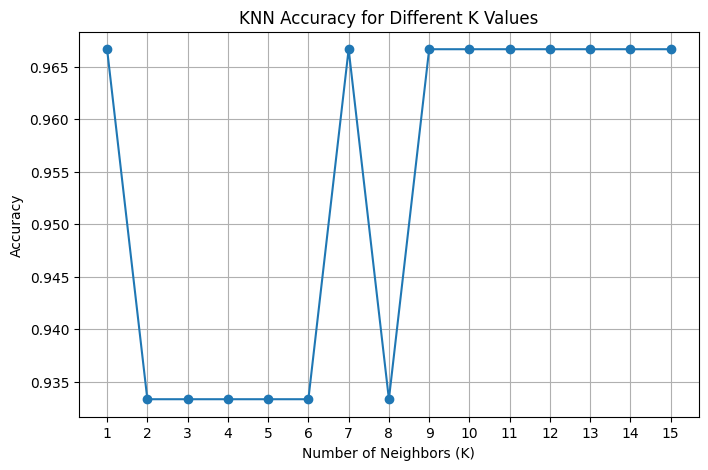

In [1]:

# Iris Flower Classification Using K-Nearest Neighbors (KNN)

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Step 2: Load Iris Dataset
iris = load_iris()

X = iris.data
y = iris.target

# Display dataset
df = pd.DataFrame(X, columns=iris.feature_names)
df['Species'] = iris.target_names[y]

print("First 5 rows of dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

# Step 3: Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Create KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)

# Step 6: Train the model
knn.fit(X_train, y_train)

# Step 7: Predict test data
y_pred = knn.predict(X_test)

# Step 8: Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

# Step 9: Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Step 10: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Iris Flower Classification - KNN")
plt.show()

# Step 11: Predict a New Iris Flower
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

new_flower_scaled = scaler.transform(new_flower)

prediction = knn.predict(new_flower_scaled)

print("\nNew Flower Measurements:", new_flower)
print("Predicted Flower Species:", iris.target_names[prediction[0]])

# Step 12: Test Different K Values
k_values = range(1, 16)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, predictions))

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o')
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

